# Desafio: Perceptron e MLP do zero
**Objetivo:** treinar um Perceptron para AND e uma rede neural para XOR, implementando os cálculos com NumPy.

## 1. Treinar um Perceptron para AND
AND retorna 1 apenas quando as duas entradas são 1. O Perceptron faz uma soma com pesos e bias, prevê a classe pelo sinal e ajusta os parâmetros quando erra.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
Y_and = np.array([-1, -1, -1, 1])

def treinar_perceptron(X, Y, taxa=0.1, max_epocas=100):
    pesos = np.zeros(X.shape[1])
    bias = 0.0
    for epoca in range(max_epocas):
        erros = 0
        for xi, yi in zip(X, Y):
            previsao = 1 if xi @ pesos + bias >= 0 else -1
            if previsao != yi:
                pesos += taxa * yi * xi
                bias += taxa * yi
                erros += 1
        if erros == 0:
            break
    return pesos, bias, epoca + 1

pesos_and, bias_and, epocas_and = treinar_perceptron(X, Y_and)
previsoes_and = np.where(X @ pesos_and + bias_and >= 0, 1, -1)
print("Previsões AND:", previsoes_and)
print("Esperado:", Y_and)
print("Épocas:", epocas_and)
print("Acertos:", (previsoes_and == Y_and).mean())

Previsões AND: [-1 -1 -1  1]
Esperado: [-1 -1 -1  1]
Épocas: 4
Acertos: 1.0


## 2. Mostrar a limitação no XOR
No XOR, entradas iguais dão 0 e diferentes dão 1. As classes ocupam cantos opostos no plano: nenhuma reta consegue separá-las, por isso um Perceptron não pode acertar as quatro combinações simultaneamente.

In [2]:
Y_xor_p = np.array([-1, 1, 1, -1])
Y = np.array([[0], [1], [1], [0]], dtype=float)
pesos_xor, bias_xor, epocas_xor = treinar_perceptron(X, Y_xor_p)
previsoes_xor_p = np.where(X @ pesos_xor + bias_xor >= 0, 1, -1)

print("Entrada | Perceptron | Esperado")
for entrada, previsao, esperado in zip(X, previsoes_xor_p, Y_xor_p):
    print(f"{entrada.astype(int)} | {previsao:>10} | {esperado:>8}")
print("Épocas:", epocas_xor)
print("Acertos:", (previsoes_xor_p == Y_xor_p).mean())

Entrada | Perceptron | Esperado
[0 0] |          1 |       -1
[0 1] |          1 |        1
[1 0] |         -1 |        1
[1 1] |         -1 |       -1
Épocas: 100
Acertos: 0.5


## 3. Construir o MLP em NumPy
A rede tem duas entradas, uma camada oculta e uma saída. Os pesos começam aleatórios e os biases em zero; a função permite variar a quantidade de neurônios ocultos.

In [3]:
def inicializar_parametros(n_entradas=2, n_ocultos=4, semente=42):
    rng = np.random.default_rng(semente)
    return {
        "W1": rng.normal(0, 0.8, size=(n_entradas, n_ocultos)),
        "b1": np.zeros((1, n_ocultos)),
        "W2": rng.normal(0, 0.8, size=(n_ocultos, 1)),
        "b2": np.zeros((1, 1))
    }

## 4. Implementar o forward
Na camada oculta, cada neurônio combina as entradas com seus pesos e bias e aplica a sigmoid, gerando `A1`. O neurônio de saída combina esses resultados e aplica a sigmoid novamente, gerando `A2`; o `cache` guarda os valores para o backward.

In [4]:
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

def forward(X, params):
    Z1 = X @ params["W1"] + params["b1"]
    A1 = sigmoid(Z1)
    Z2 = A1 @ params["W2"] + params["b2"]
    A2 = sigmoid(Z2)
    cache = {"X": X, "A1": A1, "A2": A2}
    return A2, cache

## 5. Implementar a função de perda
A binary cross-entropy mede o erro usando as saídas contínuas: valores mais próximos da resposta correta geram perdas menores. `np.mean` calcula a perda média das quatro amostras, e `np.clip` evita valores que causariam logaritmo de zero.

In [5]:
def calcular_loss(Y, saidas):
    p = np.clip(saidas, 1e-12, 1 - 1e-12)
    return float(-np.mean(Y * np.log(p) + (1 - Y) * np.log(1 - p)))

## 6. Implementar o backpropagation
Começamos pela diferença entre a saída `A2` e a resposta `Y`, considerando a média das amostras. Levamos essa informação de volta pelas conexões e pela sigmoid para calcular como cada peso e bias afeta a perda: esses valores são os gradientes.

In [6]:
def backward(Y, params, cache):
    m = len(Y)
    X, A1, A2 = cache["X"], cache["A1"], cache["A2"]
    dZ2 = (A2 - Y) / m
    dW2 = A1.T @ dZ2
    db2 = np.sum(dZ2, axis=0, keepdims=True)
    dA1 = dZ2 @ params["W2"].T
    dZ1 = dA1 * A1 * (1 - A1)
    dW1 = X.T @ dZ1
    db1 = np.sum(dZ1, axis=0, keepdims=True)
    return {"W1": dW1, "b1": db1, "W2": dW2, "b2": db2}

## 7. Treinar a rede
Cada época usa os quatro exemplos juntos para prever, medir a perda e calcular todos os gradientes. Só então atualizamos cada parâmetro: subtraímos dele a taxa de aprendizado multiplicada pelo seu gradiente.

In [7]:
def treinar_mlp(X, Y, n_ocultos=4, taxa=0.5, epocas=20000, semente=42):
    params = inicializar_parametros(X.shape[1], n_ocultos, semente)
    historico = []
    epocas_registradas = []

    for epoca in range(epocas):
        saidas, cache = forward(X, params)
        loss = calcular_loss(Y, saidas)
        gradientes = backward(Y, params, cache)
        if epoca % 100 == 0:
            historico.append(loss)
            epocas_registradas.append(epoca)
        for nome in params:
            params[nome] -= taxa * gradientes[nome]

    historico.append(calcular_loss(Y, forward(X, params)[0]))
    epocas_registradas.append(epocas)
    return params, historico, epocas_registradas

Treinamos a configuração principal **2 → 4 → 1**, com taxa 0,5, semente 42 e 20.000 épocas. A função começa uma rede nova a cada chamada, permitindo repetir as comparações.

In [8]:
params, historico_loss, epocas_registradas = treinar_mlp(X, Y)
print("Perda inicial:", historico_loss[0])
print("Perda final:", historico_loss[-1])
print("Formatos dos parâmetros:")
for nome, valor in params.items():
    print(nome, valor.shape)

Perda inicial: 0.7284818673313265
Perda final: 0.0007277815694068819
Formatos dos parâmetros:
W1 (2, 4)
b1 (1, 4)
W2 (4, 1)
b2 (1, 1)


## 8. Visualizar a curva de perda
O gráfico mostra como a perda média mudou durante o treinamento. O último ponto registra a perda após a última atualização.

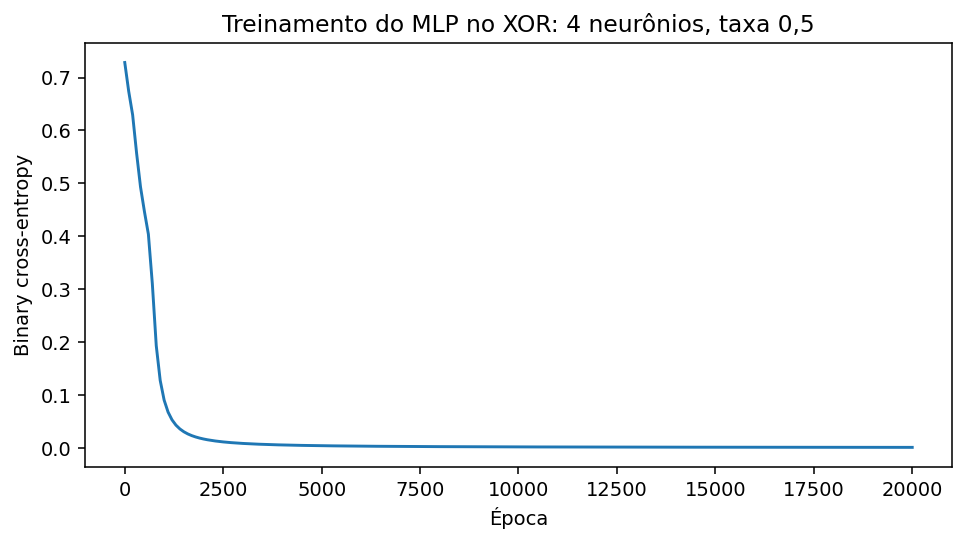

In [9]:
plt.figure(figsize=(7, 4))
plt.plot(epocas_registradas, historico_loss)
plt.xlabel("Época")
plt.ylabel("Binary cross-entropy")
plt.title("Treinamento do MLP no XOR: 4 neurônios, taxa 0,5")
plt.tight_layout()
plt.show()

## 9. Verificar as previsões
Aplicamos o limite de 0,5 às saídas da sigmoid e comparamos as classes com a tabela do XOR. Os acertos abaixo se referem às quatro combinações utilizadas no treinamento.

In [10]:
saidas, _ = forward(X, params)
previsoes = (saidas >= 0.5).astype(int)
print("Entrada | Saída da rede | Previsão | Esperado")
for entrada, saida, previsao, esperado in zip(X, saidas, previsoes, Y):
    print(f"{entrada.astype(int)} | {saida[0]:.4f} | {previsao[0]} | {int(esperado[0])}")
print(f"Acertos: {(previsoes == Y).mean():.0%}")

Entrada | Saída da rede | Previsão | Esperado
[0 0] | 0.0002 | 0 | 0
[0 1] | 0.9994 | 1 | 1
[1 0] | 0.9991 | 1 | 1
[1 1] | 0.0013 | 0 | 0
Acertos: 100%


## 10. Variar os neurônios ocultos
Comparamos 1, 2, 4 e 8 neurônios, mantendo a taxa em 0,5, a semente em 42 e 20.000 épocas. Mostramos a perda final e a porcentagem de acertos de cada execução.

In [11]:
resultados_ocultos = []
print(f"{'Neurônios':>10} {'Perda final':>14} {'Acertos':>10}")
for n_ocultos in [1, 2, 4, 8]:
    p, historico, _ = treinar_mlp(X, Y, n_ocultos=n_ocultos)
    classes = (forward(X, p)[0] >= 0.5).astype(int)
    acertos = (classes == Y).mean()
    resultados_ocultos.append((n_ocultos, historico[-1], acertos))
    print(f"{n_ocultos:>10} {historico[-1]:>14.6f} {acertos:>10.0%}")

 Neurônios    Perda final    Acertos
         1       0.477953        75%
         2       0.001836       100%
         4       0.000728       100%
         8       0.000532       100%


## 11. Variar a taxa de aprendizado
Mantemos quatro neurônios ocultos, a semente 42 e 20.000 épocas. Alteramos apenas a taxa para observar como o tamanho dos passos afeta o resultado nesse tempo de treinamento.

In [12]:
resultados_taxas = []
print(f"{'Taxa':>10} {'Perda final':>14} {'Acertos':>10}")
for taxa in [0.01, 0.1, 0.5]:
    p, historico, _ = treinar_mlp(X, Y, taxa=taxa)
    classes = (forward(X, p)[0] >= 0.5).astype(int)
    acertos = (classes == Y).mean()
    resultados_taxas.append((taxa, historico[-1], acertos))
    print(f"{taxa:>10.2f} {historico[-1]:>14.6f} {acertos:>10.0%}")

      Taxa    Perda final    Acertos
      0.01       0.492868        75%
      0.10       0.005273       100%
      0.50       0.000728       100%


## 12. Explicar como a rede aprendeu
O forward calculou as previsões, a BCE mediu o erro e o backpropagation calculou os gradientes pela regra da cadeia. A descida do gradiente ajustou pesos e biases, reduzindo a perda de **0.7285** para **0.000728** e produzindo as classes **0, 1, 1, 0**.

O Perceptron aprendeu AND, cuja separação é linear. No XOR, a camada oculta com sigmoid criou uma representação que permitiu ao MLP separar as classes.

Nos experimentos com semente 42 e 20.000 épocas, um neurônio oculto acertou **75%** dos casos; as redes com 2, 4 e 8 acertaram os quatro. Com quatro neurônios, a taxa 0,01 terminou com **75%** de acertos, enquanto 0,1 e 0,5 chegaram a 100%. Essas comparações mostram que a arquitetura e a taxa influenciam o aprendizado nas condições usadas.